# 02 · The RL environment

Every AV in a city area is an agent, and one policy drives them all. This notebook walks through the environment API: what an
observation is, what a policy returns, what the reward is made of, and how to change it. About 2 minutes on a laptop CPU.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())

av_world 0.4.0 in /home/user/av_world


## Make an environment

`av_world.make(area, n_envs, beh)` builds the area (here Oakland, Pittsburgh) and runs `n_envs` independent copies of it in one
compiled call. `beh` sets the world: the share of AVs, the demand, the human mistake rates (see `xnet.sim.Behaviour`).
`reset(warm_s=...)` fills the streets with traffic before the agents' clock starts.

In [2]:
env = av_world.make("oakland", n_envs=4, beh=dict(p_av=0.3))
state = env.reset(seed=0, warm_s=60)
print("vehicle slots per copy:", state.alive.shape[1], "  alive now:", np.asarray(state.alive.sum(1)), "  AVs:", np.asarray((state.alive & state.av).sum(1)))

vehicle slots per copy: 1024   alive now: [101 101 109  98]   AVs: [34 26 24 17]


## One step

A policy is any JAX function `f(obs [N, 28], key) -> (u [N, 2], aux)`, called on every vehicle slot of a copy at once (rows that are
not live AVs are masked out by `valid`). `u[:, 0]` in [-1, 1] is the acceleration command (+1 = +3 m/s², -1 = -8 m/s²), `u[:, 1]`
the gap acceptance at the next junction. The command goes through a safety envelope (`shield="idm"`, or `"cbf"`, `"off"`).

Here the bundled PPO policy (`av_world.load_policy()`) drives.

In [3]:
policy = av_world.load_policy()
state, tr = env.step(state, policy)
print({k: tuple(v.shape) for k, v in tr.items() if hasattr(v, "shape")})
valid = np.asarray(tr["valid"])
print(f"{valid.sum()} AV transitions in this step (all copies), reward of the first few: {np.asarray(tr['reward'])[valid][:6].round(3)}")

{'a_rule': (4, 1024), 'aux': (4, 1024, 2), 'bar_cut': (4, 1024), 'bar_h': (4, 1024), 'bar_reach': (4, 1024), 'bar_veto_j': (4, 1024), 'bar_veto_m': (4, 1024), 'crash': (4, 1024), 'done': (4, 1024), 'margins': (4, 1024, 5), 'near': (4, 1024), 'obs': (4, 1024, 28), 'red': (4, 1024), 'reward': (4, 1024), 'u': (4, 1024, 2), 'valid': (4, 1024)}
101 AV transitions in this step (all copies), reward of the first few: [ 0.059  0.096 -0.073  0.057  0.085  0.089]


### What an AV sees

The 28 features are named in `av_world.sil.OBS_NAMES` (scaled to roughly [0, 1]). The first live AV of copy 0:

In [4]:
from av_world.sil import OBS_NAMES
obs = np.asarray(tr["obs"][0]); i = int(np.nonzero(valid[0])[0][0])
for n, v in zip(OBS_NAMES, obs[i]):
    print(f"  {n:42s} {v:7.3f}")
print("command u:", np.asarray(tr["u"][0, i]).round(3))

  speed/15                                     0.024
  accel/3                                     -0.160
  speed limit/15                               0.745
  desired speed/15                             0.468
  distance to end of lane/100                  0.007
  on a link (0: in a junction)                 1.000
  has a stop target                            1.000
  stop target gap/100                          0.026
  has a leader                                 0.000
  leader gap/50                                3.000
  leader speed/15                              0.000
  closing speed/10                             0.000
  red ahead                                    1.000
  yellow ahead                                 0.000
  stop sign ahead                              0.000
  must yield                                   1.000
  junction speed cap/15                        0.458
  gap acceptable                               1.000
  room after the junction                     

## Roll out and compare policies

`env.rollout(state, policy, steps)` is a `lax.scan` of steps. Three policies on the same start state for 2 simulated minutes:
the trained policy, a timid one (always brake gently) and the rule-based AV (`policy=None` is the simulator's own driver; it
returns no transitions, so its numbers come from the counters).

In [5]:
import jax.numpy as jnp
from avrl import xppo as P
from xnet import sim as X

def timid(obs, key):
    u0 = jnp.where(obs[:, 0] > 0.4, -0.1, 0.2)       # crawl: accelerate below 6 m/s, brake gently above it
    return jnp.stack([u0, jnp.ones_like(u0)], 1), jnp.zeros((obs.shape[0], 2))

start = state
rows = {}
for name, pol in (("PPO (bundled)", policy), ("timid", timid), ("rule-based", None)):
    t = time.time()
    m0 = np.asarray(start.m).sum(0)
    s, traj = env.rollout(start, pol, steps=600)
    d = P.summarize(np.asarray(s.m).sum(0) - m0)
    r = float(np.asarray(traj["reward"]).sum() / max(np.asarray(traj["valid"]).sum(), 1)) if traj is not None else float("nan")
    rows[name] = dict(reward_per_step=r, **d)
    print(f"{name:14s} reward/AV-step {r:7.4f}  AV speed {d['av_speed_kmh']:5.1f} km/h  AV hours {d['av_hours']:5.1f}  "
          f"AV crashes {d['av_crashes']}  hard brakes/h {d['av_hard_per_h']:5.1f}  ({time.time() - t:.0f} s)")

PPO (bundled)  reward/AV-step  0.0817  AV speed  23.9 km/h  AV hours   7.3  AV crashes 0  hard brakes/h   2.7  (15 s)


timid          reward/AV-step  0.0566  AV speed  16.3 km/h  AV hours   7.4  AV crashes 0  hard brakes/h   1.9  (13 s)


rule-based     reward/AV-step     nan  AV speed  22.8 km/h  AV hours   7.3  AV crashes 0  hard brakes/h  17.8  (13 s)


## The reward, and how to change it

The per-step reward is a weighted sum (`xnet.sim.Reward`): progress per metre, penalties for idling, discomfort, hard braking, jerk,
short headways, speeding, leaning on the safety envelope, and large penalties for a crash (-30), a red light (-20) or a junction
entry ahead of a car with priority (-3). The weights are read when the step is compiled, so set `X.R` and build a fresh
environment.

In [6]:
for k, v in X.Reward()._asdict().items():
    print(f"  {k:9s} {v:9.5f}")

  progress    0.02000
  idle        0.05000
  team        0.01000
  comfort     0.00100
  hard        0.20000
  jerk        0.00004
  headway     0.10000
  speed       0.10000
  shield      0.04000
  crash     -30.00000
  red       -20.00000
  near       -3.00000
  barrier     0.00000
  inside      0.00000
  veto        0.00000
  cruise      0.00000


In [7]:
X.R = X.Reward(speed=1.0, progress=0.01)            # 10x the speeding penalty, half the progress reward
env_strict = av_world.make("oakland", n_envs=4, beh=dict(p_av=0.3))
s, traj = env_strict.rollout(start, policy, steps=600)
r_strict = float(np.asarray(traj["reward"]).sum() / np.asarray(traj["valid"]).sum())
X.R = X.Reward()                                      # back to the default for the rest of the session
print(f"same policy, same start: reward/AV-step {rows['PPO (bundled)']['reward_per_step']:.4f} (default) vs {r_strict:.4f} (strict)")
print("train on it: avrl.xppo.train(..., reward={'speed': 1.0, 'progress': 0.01})  (notebook 03)")

same policy, same start: reward/AV-step 0.0817 (default) vs 0.0622 (strict)
train on it: avrl.xppo.train(..., reward={'speed': 1.0, 'progress': 0.01})  (notebook 03)


## What the trained policy does with what it sees

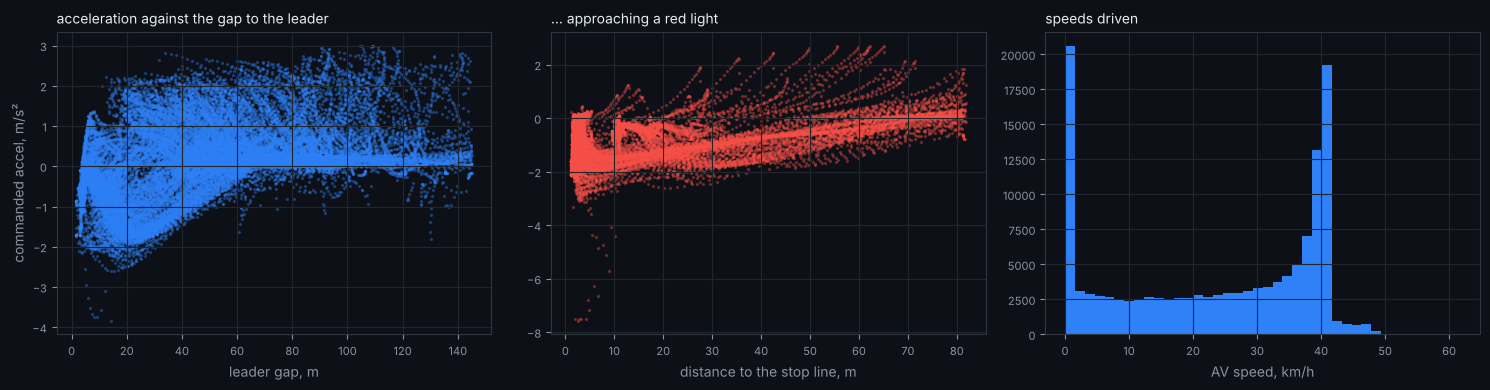

In [8]:
plt.rcParams.update({"axes.titlecolor": "#e6edf3", "axes.labelcolor": "#8b949e"})
def dark(ax):
    ax.set_facecolor("#0d1117"); ax.tick_params(colors="#8b949e", labelsize=8); ax.grid(color="#21262d")
    for s in ax.spines.values(): s.set_color("#30363d")
    ax.title.set_color("#e6edf3"); ax.xaxis.label.set_color("#8b949e"); ax.yaxis.label.set_color("#8b949e")
o = np.asarray(traj["obs"]).reshape(-1, 28); v = np.asarray(traj["valid"]).reshape(-1)
u = np.asarray(traj["u"]).reshape(-1, 2)[v]; o = o[v]
fig, axs = plt.subplots(1, 3, figsize=(15, 4), facecolor="#0d1117")
acc = np.where(u[:, 0] >= 0, 3 * u[:, 0], 8 * u[:, 0]).clip(-8, 3)
lead = (o[:, 8] > 0.5) & (o[:, 9] < 2.9)           # a leader in range (3.0 = none: a placeholder)
axs[0].scatter(50 * o[lead, 9], acc[lead], s=2, alpha=0.3, c="#2f81f7"); axs[0].set_xlabel("leader gap, m"); axs[0].set_ylabel("commanded accel, m/s²")
axs[0].set_title("acceleration against the gap to the leader", loc="left", fontsize=10)
red = (o[:, 12] > 0.5) & (o[:, 7] < 2.9)          # a red light ahead with a stop line in range
axs[1].scatter(100 * o[red, 7], acc[red], s=2, alpha=0.3, c="#f85149"); axs[1].set_xlabel("distance to the stop line, m")
axs[1].set_title("... approaching a red light", loc="left", fontsize=10)
axs[2].hist(15 * 3.6 * o[:, 0], bins=40, color="#2f81f7"); axs[2].set_xlabel("AV speed, km/h"); axs[2].set_title("speeds driven", loc="left", fontsize=10)
for a in axs: dark(a)
fig.tight_layout(); display(fig); plt.close(fig)

## Next

* [03 PPO training](03_ppo_training.ipynb): train a policy on this environment and score it.
* The same environment is reachable from another process or machine (your own stack in C++ or ROS):
  [docs/SIL_HIL.md](../docs/SIL_HIL.md).
* Other areas: `new_york`, `chicago`, `boston`, `squirrel_hill`, `downtown`, any OpenStreetMap file or a bounding box.